# PlantSeg v7: Data Preparation and Experimental Protocol / 数据准备与实验协议

**AIP304 CW2, Option 2 - Member 1.** Team names and student IDs: TODO.

**AIP304 CW2，选项 2 — 成员 1。** 组员姓名与学号：待填写（TODO）。

This notebook preserves the student's metadata, role-mapping and duplicate-exclusion logic, and completes the reproducible preparation pipeline. Run from top to bottom on CPU. Every code cell has a short English explanation and a task-sheet section reference.

本笔记本保留学生原有的元数据、角色映射与重复样本排除逻辑，并补全可复现的数据准备流程。请在 CPU 上从上到下依次运行。每个代码单元格都配有一段简短的英文说明，并标注任务书章节引用。

**Task-sheet guide:** Section 2.1 defines the dataset and nine-host subset; Section 2.2 requires the original partitions, integrity checks and leakage prevention; Section 4.2 defines Assignment A and unknown groups (continued on p. 5); Section 5.1(5) defines Assignment B and mask restrictions; Sections 6.1, 6.3 and 6.5 cover reproducibility, figures and AI disclosure.

**任务书指引：** 第 2.1 节定义数据集与九种宿主子集；第 2.2 节要求保留原始划分、进行完整性检查并防止泄漏；第 4.2 节定义任务 A 与未知类别组（续至第 5 页）；第 5.1(5) 节定义任务 B 与掩膜限制；第 6.1、6.3 和 6.5 节涉及可复现性、图表与 AI 使用披露。

**Scope:** prepare and export data only. No model training, calibration or test-performance calculation. The source labels, URLs and licences are retained. The exported protocol remains **draft** until the team reviews the documented exclusions and freezes the experimental protocol before training.

**范围：** 仅做数据准备与导出，不涉及模型训练、校准或测试性能计算。源标签、URL 与许可协议均予保留。在团队复核所记录的排除规则、并在训练前冻结实验协议之前，导出的协议保持**草稿（draft）**状态。

**Setup:** install `pandas numpy Pillow matplotlib nbformat nbclient ipykernel` if needed. Obtain `plantseg.zip` from [Zenodo record 17719108](https://zenodo.org/records/17719108) (v7, 2025-11-25), place it in `data/raw/`, and extract its `plantseg/` folder under `data/raw/plantseg-v7/`. Existing raw files are never changed here. Set `CW2_PROJECT_ROOT`, `PLANTSEG_DATA_ROOT`, `PLANTSEG_ARCHIVE` or `CW2_OUTPUT_ROOT` before running to use Colab/Kaggle or another local layout. No private absolute paths are stored in this notebook.


**环境准备：** 如需要，请安装 `pandas numpy Pillow matplotlib nbformat nbclient ipykernel`。从 [Zenodo 记录 17719108](https://zenodo.org/records/17719108)（v7，2025-11-25）获取 `plantseg.zip`，放到 `data/raw/`，并将其中的 `plantseg/` 文件夹解压到 `data/raw/plantseg-v7/` 下。此处绝不会改动已有原始文件。若要在 Colab/Kaggle 或其他本地目录结构下运行，请在运行前设置 `CW2_PROJECT_ROOT`、`PLANTSEG_DATA_ROOT`、`PLANTSEG_ARCHIVE` 或 `CW2_OUTPUT_ROOT`。本笔记本不保存任何私有的绝对路径。

### 1. Paths and environment 路径与环境 - Sections 2.2(4), 6.1

Configure portable paths, record the actual software environment, and create output folders. The display seed controls training-only examples, not dataset partitions.

配置可移植的路径、记录实际软件环境，并创建输出文件夹。显示种子（display seed）只控制仅用于训练的可视化示例，不影响数据集划分。

In [1]:
from pathlib import Path, PurePosixPath
from datetime import datetime, timezone, timedelta
import os, sys, platform, json, hashlib, zipfile, zlib, time
import importlib.metadata
import numpy as np
import pandas as pd
from PIL import Image, ImageOps
import matplotlib.pyplot as plt
from IPython.display import display

START_TIME = time.perf_counter()
RUN_AT = datetime.now(timezone(timedelta(hours=8))).isoformat()
learn_project_root = Path(os.environ.get("CW2_PROJECT_ROOT", ".")).resolve()
learn_data_root = Path(os.environ.get(
    "PLANTSEG_DATA_ROOT", str(learn_project_root / "data/raw/plantseg-v7/plantseg")
)).resolve()
archive_path = Path(os.environ.get(
    "PLANTSEG_ARCHIVE", str(learn_project_root / "data/raw/plantseg.zip")
)).resolve()
ART = Path(os.environ.get("CW2_OUTPUT_ROOT", str(learn_project_root / "artifacts"))).resolve()
for folder in ["metadata", "audit", "splits", "figures"]:
    (ART / folder).mkdir(parents=True, exist_ok=True)
learn_metadata_path = learn_data_root / "Metadata.csv"
DISPLAY_SEED = 304


def digest_file(path, algorithm="sha256"):
    digest = hashlib.new(algorithm)
    with Path(path).open("rb") as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()


def save_json(path, value):
    Path(path).write_text(json.dumps(value, indent=2, ensure_ascii=False, allow_nan=False) + "\n", encoding="utf-8")


def save_csv(frame, path):
    frame.to_csv(path, index=False, lineterminator="\n")


environment = {
    "run_at": RUN_AT, "python": sys.version, "platform": platform.platform(),
    "device": "CPU", "display_seed": DISPLAY_SEED,
    "packages": {name: importlib.metadata.version(name) for name in
                 ["pandas", "numpy", "Pillow", "matplotlib", "nbformat", "nbclient", "ipykernel"]}
}
assert learn_metadata_path.is_file(), "Configure PLANTSEG_DATA_ROOT or extract the v7 dataset first."
save_json(ART / "metadata/environment.json", environment)
print("Dataset metadata found. Outputs use the configured artifacts directory.")
display(environment)

Dataset metadata found. Outputs use the configured artifacts directory.


{'run_at': '2026-11-19T12:04:20.271701+08:00',
 'python': '3.14.7 | packaged by Anaconda, Inc. | (main, Aug 14 2026, 10:13:42) [Clang 20.1.8 ]',
 'platform': 'macOS-26.5-arm64-arm-64bit-Mach-O',
 'device': 'CPU',
 'display_seed': 304,
 'packages': {'pandas': '3.0.5',
  'numpy': '2.5.2',
  'Pillow': '12.3.0',
  'matplotlib': '3.11.1',
  'nbformat': '5.11.0',
  'nbclient': '0.11.0',
  'ipykernel': '7.3.0'}}

### 2. Verify the fixed dataset release 校验固定的数据集发布版本 - Sections 2.1, 6.1

Check the official v7 archive size and MD5, then compare the extracted metadata with that archive. A local SHA-256 is a fingerprint; it is not an independent source checksum. This cell reads existing data and never extracts or overwrites it.

核对官方 v7 压缩包的大小和 MD5，再把解压后的元数据与该压缩包比对。本地 SHA-256 只是一个文件指纹，并非独立的来源校验和。本单元格只读取已有数据，绝不重新解压或覆盖。

In [2]:
SOURCE_URL = "https://zenodo.org/records/17719108"
SOURCE_MD5 = "9358a66dff88cdd15c4fe009763c40a3"
SOURCE_SIZE = 1057281724
if not archive_path.is_file():
    raise FileNotFoundError("Place the official plantseg.zip in data/raw/ or set PLANTSEG_ARCHIVE.")

dataset_info = {
    "version": "v7", "record_id": 17719108, "source_url": SOURCE_URL,
    "publication_date": "2025-11-25", "file_name": "plantseg.zip", "checked_at": RUN_AT,
    "source_checksum": "md5:" + SOURCE_MD5, "checksum_status": "unverified",
    "downloaded_at": None, "download_date_note": "Existing archive reused; acquisition time not inferred from filesystem timestamps.",
    "file_size_bytes": archive_path.stat().st_size,
    "local_md5": digest_file(archive_path, "md5"), "local_sha256": digest_file(archive_path)
}
if dataset_info["file_size_bytes"] != SOURCE_SIZE or dataset_info["local_md5"] != SOURCE_MD5:
    dataset_info["checksum_status"] = "failed"
    save_json(ART / "metadata/dataset_info.json", dataset_info)
    raise ValueError("Archive failed official v7 verification. Do not use this archive.")
with zipfile.ZipFile(archive_path) as release:
    if release.read("plantseg/Metadata.csv") != learn_metadata_path.read_bytes():
        raise ValueError("Extracted metadata differs from the verified v7 archive.")
dataset_info["checksum_status"] = "verified"
save_json(ART / "metadata/dataset_info.json", dataset_info)
display(dataset_info)

{'version': 'v7',
 'record_id': 17719108,
 'source_url': 'https://zenodo.org/records/17719108',
 'publication_date': '2025-11-25',
 'file_name': 'plantseg.zip',
 'checked_at': '2026-11-19T12:04:20.271701+08:00',
 'source_checksum': 'md5:9358a66dff88cdd15c4fe009763c40a3',
 'checksum_status': 'verified',
 'downloaded_at': None,
 'download_date_note': 'Existing archive reused; acquisition time not inferred from filesystem timestamps.',
 'file_size_bytes': 1057281724,
 'local_md5': '9358a66dff88cdd15c4fe009763c40a3',
 'local_sha256': 'cbdfb273eb26fea93fda52bbfe4766cc31881feb3a1202b13e4d85e8a4c0bcfa'}

### 3. Read metadata and select nine hosts 读取元数据并筛选九种宿主 - Section 2.1

Each metadata row identifies one image. Keep raw Plant/Disease fields, normalise host names, and select exactly the nine coursework hosts. Source URLs and licences remain available for attribution.

元数据每一行对应一张图像。保留原始的 Plant/Disease 字段，规范化宿主名称，并精确筛选出课业要求的九种宿主。源 URL 与许可信息保留在表中，供标注出处使用。

In [3]:
learn_meta = pd.read_csv(learn_metadata_path, keep_default_na=False)
required = {"Name", "Index", "Plant", "Disease", "Label file", "Split", "URL", "License"}
assert required.issubset(learn_meta.columns), "Unexpected metadata schema."
assert learn_meta["Name"].is_unique and learn_meta["Name"].ne("").all()
assert set(learn_meta["Split"]).issubset({"Training", "Validation", "Test"})
display(learn_meta[["Name", "Plant", "Disease", "Index", "Label file", "Split"]].head(5))
learn_hosts = [
    "apple", "banana", "citrus",
    "corn", "potato", "soybean",
    "tomato", "wheat", "zucchini"
]

learn_meta["host"] = (
    learn_meta["Plant"]
    .str.strip()
    .str.lower()
)

learn_selected = learn_meta.loc[
    learn_meta["host"].isin(learn_hosts)
].copy()

print("amount of pics before selected: ", len(learn_meta))
print("amount of pics after selected: ", len(learn_selected))
print("amount of hosts after selected: ", learn_selected["host"].nunique())
print("actual hosts: ", sorted(learn_selected["host"].unique()))

assert set (learn_selected["host"]) == set(learn_hosts), "缺少某些 host，请检查数据"

,Name,Plant,Disease,Index,Label file,Split
0,apple_black_rot_1.jpg,Apple,apple black rot,0,apple_black_rot_1.png,Training
1,apple_black_rot_11.jpg,Apple,apple black rot,0,apple_black_rot_11.png,Training
2,apple_black_rot_12.jpg,Apple,apple black rot,0,apple_black_rot_12.png,Training
3,apple_black_rot_15.jpg,Apple,apple black rot,0,apple_black_rot_15.png,Training
4,apple_black_rot_156.jpg,Apple,apple black rot,0,apple_black_rot_156.png,Training


amount of pics before selected:  7774
amount of pics after selected:  4349
amount of hosts after selected:  9
actual hosts:  ['apple', 'banana', 'citrus', 'corn', 'potato', 'soybean', 'tomato', 'wheat', 'zucchini']


### 4. Derive host-disease classes 推导「宿主-病害」类别 - Sections 2.1, 4.2

Remove the exact host prefix from Disease after normalising whitespace and case. Preserve original labels and check for accidental label merges. Roles are constructed from the complete metadata taxonomy before any file exclusions.

在规范化空白字符与大小写之后，从 Disease 字段中剔除完全匹配的宿主前缀。保留原始标签，并检查是否发生意外的标签合并。类别角色基于完整的元数据分类体系构建，且在任何文件排除之前完成。

In [4]:
learn_diseases = []

for host, raw_label in zip(
    learn_selected["host"],
    learn_selected["Disease"]
):
    label = " ".join(raw_label.strip().lower().split())
    prefix = host + " "

    if not label.startswith(prefix):
        raise ValueError(f"疾病标签 '{label}' 不以宿主 '{host}' 开头，请检查数据")

    disease = label[len(prefix):]
    learn_diseases.append(disease)

learn_selected["disease"] = learn_diseases

display(
    learn_selected[["Plant", "host", "Disease", "disease"]].drop_duplicates().head(10)
)

learn_classes=(
    learn_selected[["host", "disease"]]
    .drop_duplicates()
    .sort_values(["host", "disease"])
    .reset_index(drop=True)
)

print("amount of classes: ", len(learn_classes))

display(learn_classes)

label_mapping = learn_selected[["Plant", "Disease", "host", "disease", "Index"]].drop_duplicates()
assert not label_mapping.duplicated(["host", "disease"]).any(), "Normalisation merged source labels."
assert label_mapping["Index"].is_unique
assert len(learn_classes) == 43, "Actual taxonomy differs from the task-sheet expectation; investigate."
save_csv(label_mapping, ART / "metadata/label_normalisation.csv")
display(learn_classes.groupby("host").size().rename("class_count"))

,Plant,host,Disease,disease
0,Apple,apple,apple black rot,black rot
51,Apple,apple,apple mosaic virus,mosaic virus
111,Apple,apple,apple rust,rust
187,Apple,apple,apple scab,scab
320,Banana,banana,banana anthracnose,anthracnose
361,Banana,banana,banana black leaf streak,black leaf streak
450,Banana,banana,banana bunchy top,bunchy top
515,Banana,banana,banana cigar end rot,cigar end rot
539,Banana,banana,banana cordana leaf spot,cordana leaf spot
561,Banana,banana,banana panama disease,panama disease


amount of classes:  43


,host,disease
0,apple,black rot
1,apple,mosaic virus
2,apple,rust
3,apple,scab
4,banana,anthracnose
5,banana,black leaf streak
6,banana,bunchy top
7,banana,cigar end rot
8,banana,cordana leaf spot
9,banana,panama disease


host
apple       4
banana      6
citrus      2
corn        4
potato      2
soybean     6
tomato      7
wheat       8
zucchini    4
Name: class_count, dtype: int64

### 5. Count original partitions 统计原始分区 - Sections 2.2(1), 6.3

Count images for every host and class across the supplied partitions, including zero counts. These are raw counts before exclusions. Verify that class totals and partition totals agree.

统计每个宿主、每个类别在给定分区中的图像数量（含数量为零的情况）。这些是排除之前的原始计数。并核对类别合计与各分区合计是否一致。

In [5]:
print("原始分区名称：", learn_selected["Split"].unique())

learn_split_counts = (
    learn_selected["Split"]
    .value_counts()
    .reindex(["Training", "Validation", "Test"], fill_value=0)
)

display(learn_split_counts)

learn_split_percent = (
    learn_split_counts / learn_split_counts.sum() * 100
).round(2)

display(learn_split_percent.rename("percent"))

learn_host_counts = (
    learn_selected
    .groupby(["host", "Split"])
    .size()
    .unstack("Split", fill_value=0)
    .reindex(
        index=learn_hosts,
        columns=["Training", "Validation", "Test"],
        fill_value=0
    )
)

display(learn_host_counts)

learn_class_counts = (
    learn_selected
    .groupby(["host", "disease", "Split"])
    .size()
    .unstack("Split", fill_value=0)
    .reindex(
        columns=["Training", "Validation", "Test"],
        fill_value=0
    )
)

learn_class_counts["Total"] = (
    learn_class_counts[
        ["Training", "Validation", "Test"]
    ].sum(axis=1)
)

display(learn_class_counts)

assert len(learn_class_counts) == len(learn_classes), "类别数量不匹配，请检查数据"

assert (
    learn_class_counts["Total"].sum()
    == len(learn_selected)
)

assert (
    learn_class_counts[
        ["Training", "Validation", "Test"]
    ].sum(axis=0)
    .eq(learn_split_counts)
    .all()
)

print("检查通过：类别数量、图片总数和各分区数量一致")

learn_zero_partition_classes = learn_class_counts.loc[
    learn_class_counts[
        ["Training", "Validation", "Test"]
    ].eq(0).any(axis=1)
]

print("至少一个原始分区为零的类别数：",
      len(learn_zero_partition_classes))

display(learn_zero_partition_classes)

原始分区名称： <StringArray>
['Training', 'Validation', 'Test']
Length: 3, dtype: str


Split
Training      3007
Validation     475
Test           867
Name: count, dtype: int64

Split
Training      69.14
Validation    10.92
Test          19.94
Name: percent, dtype: float64

Split,Training,Validation,Test
host,,,
apple,274,46,82
banana,244,36,74
citrus,291,42,83
corn,289,46,84
potato,103,16,27
soybean,356,46,98
tomato,460,74,133
wheat,798,137,231
zucchini,192,32,55


Split                                         Training  Validation  Test  \
host     disease                                                           
apple    black rot                                  43           8    12   
         mosaic virus                               52           8    13   
         rust                                       64          12    22   
         scab                                      115          18    35   
banana   anthracnose                                35           6     9   
         black leaf streak                          79          10    25   
         bunchy top                                 56           9    13   
         cigar end rot                              22           2     9   
         cordana leaf spot                          19           3     8   
         panama disease                             33           6    10   
citrus   canker                                    225          33    65   
         greening disease                           66           9    18   
corn     gray leaf spot                             49          10    17   
         northern leaf blight                       65           9    18   
         rust                                       84          13    23   
         smut                                       91          14    26   
potato   early blight                               50           9     9   
         late blight                                53           7    18   
soybean  bacterial blight                           41           6    14   
         brown spot                                 42           3    10   
         downy mildew                               56           6    14   
         frog eye leaf spot                        111          13    29   
         mosaic                                     61          11    17   
         rust                                       45           7    14   
tomato   bacterial leaf spot                        64           9    17   
         early blight                              103          16    34   
         late blight                                84          14    19   
         leaf mold                                  71          13    18   
         mosaic virus                               29           5     9   
         septoria leaf spot                         66          13    20   
         yellow leaf curl virus                     43           4    16   
wheat    bacterial leaf streak (black chaff)        53          11    19   
         head scab                                 161          25    44   
         leaf rust                                  53           7    15   
         loose smut                                101          15    25   
         powdery mildew                            119          24    35   
         septoria blotch                            95          19    28   
         stem rust                                  56          11    22   
         stripe rust                               160          25    43   
zucchini bacterial wilt                             38           7    12   
         downy mildew                               25           3     5   
         powdery mildew                             90          16    27   
         yellow mosaic virus                        39           6    11   

Split                                         Total  
host     disease                                     
apple    black rot                               63  
         mosaic virus                            73  
         rust                                    98  
         scab                                   168  
banana   anthracnose                             50  
         black leaf streak                      114  
         bunchy top                              78  
         cigar end rot                           33  
         cordana leaf spot             

检查通过：类别数量、图片总数和各分区数量一致
至少一个原始分区为零的类别数： 0


,Split,Training,Validation,Test,Total
host,disease,,,,


### 6. Assign class roles for A 为任务 A 分配类别角色 - Section 4.2

Keep all citrus classes as development unknowns and potato as test unknowns. For the other seven hosts, reserve disease positions 1 and 2. Disease ordering is lowercase Unicode ascending; apple is checked against the task-sheet example.

将柑橘（citrus）的所有类别保留为开发阶段未知类别，马铃薯（potato）作为测试阶段未知类别。对另外七种宿主，保留排序第 1 和第 2 的病害类别。病害按小写 Unicode 升序排列；苹果的分配结果会与任务书示例进行核对。

In [6]:
#assignment A
# 任务 A（Assignment A）：为每个「宿主-病害」类别分配角色
learn_roles_A = (
    learn_classes
    .sort_values(["host", "disease"])
    .reset_index(drop=True)
    .copy()
)

learn_roles_A["disease_rank"] = (
    learn_roles_A.groupby("host").cumcount() + 1
)

display(learn_roles_A)

learn_roles_A["class_role"] = "known"

learn_familiar_host = ~learn_roles_A["host"].isin(["citrus", "potato"])

learn_roles_A.loc[
    learn_familiar_host & learn_roles_A["disease_rank"].eq(1),
    "class_role"
] = "development_unknown"

learn_roles_A.loc[
    learn_familiar_host
    & learn_roles_A["disease_rank"].eq(2),
    "class_role"
] = "test_unknown"

learn_roles_A.loc[
    learn_roles_A["host"].eq("citrus"),
    "class_role"
] = "development_unknown"

learn_roles_A.loc[
    learn_roles_A["host"].eq("potato"),
    "class_role"
] = "test_unknown"

learn_apple_A = learn_roles_A.loc[
    learn_roles_A["host"].eq("apple"),
    ["host", "disease", "class_role"]
]

display(learn_apple_A)

learn_expected_apple_A = {
    "black rot": "development_unknown",
    "mosaic virus": "test_unknown",
    "rust": "known",
    "scab": "known"
}

learn_actual_apple_A = (
    learn_apple_A
    .set_index("disease")["class_role"]
    .to_dict()
)

assert learn_actual_apple_A == learn_expected_apple_A

assert learn_roles_A.loc[
    learn_roles_A["host"].eq("citrus"),
    "class_role"
].eq("development_unknown").all()

assert learn_roles_A.loc[
    learn_roles_A["host"].eq("potato"),
    "class_role"
].eq("test_unknown").all()

assert not learn_roles_A.duplicated(
    ["host", "disease"]
).any()

assert len(learn_roles_A) == len(learn_classes)

display(learn_roles_A["class_role"].value_counts())

,host,disease,disease_rank
0,apple,black rot,1
1,apple,mosaic virus,2
2,apple,rust,3
3,apple,scab,4
4,banana,anthracnose,1
5,banana,black leaf streak,2
6,banana,bunchy top,3
7,banana,cigar end rot,4
8,banana,cordana leaf spot,5
9,banana,panama disease,6


,host,disease,class_role
0,apple,black rot,development_unknown
1,apple,mosaic virus,test_unknown
2,apple,rust,known
3,apple,scab,known


class_role
known                  25
development_unknown     9
test_unknown            9
Name: count, dtype: int64

### 7. Assign class roles for B 为任务 B 分配类别角色 - Section 5.1(5)

Use disease positions 2 and 3 for the seven familiar hosts, retaining the citrus/potato roles. Compare both mappings before any exclusions; every class must have exactly one role in each assignment.

对七种熟悉宿主改用排序第 2 和第 3 的病害类别，同时保留 citrus/potato 的角色。在排除任何文件之前比较两套映射；每个类别在每项任务中必须恰好对应一个角色。

In [7]:
#assignment B
# 任务 B（Assignment B）：为每个「宿主-病害」类别分配角色
learn_roles_B = learn_roles_A[
    ["host", "disease", "disease_rank"]
].copy()

learn_roles_B["class_role"] = "known"

learn_familiar_host_B = ~learn_roles_B["host"].isin(
    ["citrus", "potato"]
)

learn_roles_B.loc[
    learn_familiar_host_B
    & learn_roles_B["disease_rank"].eq(2),
    "class_role"
] = "development_unknown"

learn_roles_B.loc[
    learn_familiar_host_B
    & learn_roles_B["disease_rank"].eq(3),
    "class_role"
] = "test_unknown"

learn_roles_B.loc[
    learn_roles_B["host"].eq("citrus"),
    "class_role"
] = "development_unknown"

learn_roles_B.loc[
    learn_roles_B["host"].eq("potato"),
    "class_role"
] = "test_unknown"

display(learn_roles_B.loc[
    learn_roles_B["host"].eq("apple")
])

learn_expected_apple_B = {
    "black rot": "known",
    "mosaic virus": "development_unknown",
    "rust": "test_unknown",
    "scab": "known"
}

learn_actual_apple_B = (
    learn_roles_B.loc[learn_roles_B["host"].eq("apple")]
    .set_index("disease")["class_role"]
    .to_dict()
)

assert learn_actual_apple_B == learn_expected_apple_B

assert learn_roles_B.loc[
    learn_roles_B["host"].eq("citrus"),
    "class_role"
].eq("development_unknown").all()

assert learn_roles_B.loc[
    learn_roles_B["host"].eq("potato"),
    "class_role"
].eq("test_unknown").all()

display(learn_roles_B["class_role"].value_counts())

learn_role_comparison = learn_roles_A[
    ["host", "disease", "class_role"]
].merge(
    learn_roles_B[["host", "disease", "class_role"]],
    on=["host", "disease"],
    how="outer",
    suffixes=("_A", "_B"),
    validate="one_to_one"
)

assert len(learn_role_comparison) == len(learn_classes)

assert learn_role_comparison[
    ["class_role_A", "class_role_B"]
].notna().all().all()

display(learn_role_comparison.loc[
    learn_role_comparison["host"].eq("apple")
])

learn_changed_roles = learn_role_comparison.loc[
    learn_role_comparison["class_role_A"].ne(
        learn_role_comparison["class_role_B"]
    )
]

print("A/B 角色发生变化的类别数：", len(learn_changed_roles))

display(learn_changed_roles)

roles = {"A": learn_roles_A, "B": learn_roles_B}
for assignment, table in roles.items():
    assert len(table) == len(learn_classes)
    assert not table.duplicated(["host", "disease"]).any()
    assert table["class_role"].isin(["known", "development_unknown", "test_unknown"]).all()
    counts = table.groupby("host").size()
    assert counts.drop(["citrus", "potato"]).ge(3).all()

,host,disease,disease_rank,class_role
0,apple,black rot,1,known
1,apple,mosaic virus,2,development_unknown
2,apple,rust,3,test_unknown
3,apple,scab,4,known


class_role
known                  25
development_unknown     9
test_unknown            9
Name: count, dtype: int64

,host,disease,class_role_A,class_role_B
0,apple,black rot,development_unknown,known
1,apple,mosaic virus,test_unknown,development_unknown
2,apple,rust,known,test_unknown
3,apple,scab,known,known


A/B 角色发生变化的类别数： 21


,host,disease,class_role_A,class_role_B
0,apple,black rot,development_unknown,known
1,apple,mosaic virus,test_unknown,development_unknown
2,apple,rust,known,test_unknown
4,banana,anthracnose,development_unknown,known
5,banana,black leaf streak,test_unknown,development_unknown
6,banana,bunchy top,known,test_unknown
12,corn,gray leaf spot,development_unknown,known
13,corn,northern leaf blight,test_unknown,development_unknown
14,corn,rust,known,test_unknown
18,soybean,bacterial blight,development_unknown,known


### 8. Build manifests, IDs and relative paths 构建清单、编号与相对路径 - Sections 2.2, 4.2, 5.1(5)

Use the original split together with each class role to choose train/validation/test/unused. Assign consecutive known-only output IDs independently for A and B. Paths use the original folders, never the experimental split.

结合原始划分和各类别角色来确定 train/validation/test/unused。为 A 和 B 分别独立地给仅属于已知类别的输出编号，且编号连续。路径使用原始文件夹结构，绝不使用实验划分后的目录。

In [8]:
def build_manifest(image, roles, assignment):
    manifest = image.merge(
        roles[["host", "disease", "class_role"]],
        on=["host", "disease"],
        how="left",
        validate="many_to_one"
    )

    assert len(manifest) == len(image), "manifest 的行数与 image 不匹配"
    assert manifest["Name"].is_unique
    assert manifest["class_role"].notna().all()

    manifest["assignment"] = assignment
    manifest["experimental_split"] = "unused"

    known = manifest["class_role"].eq("known")

    split_names = {
        "Training": "train",
        "Validation": "validation",
        "Test": "test"
    }

    manifest.loc[
        known,
        "experimental_split"
    ] = (
        manifest.loc[known, "Split"]
        .map(split_names)
    )

    dev_validation = (
        manifest["class_role"].eq("development_unknown")
        & manifest["Split"].eq("Validation")
    )

    manifest.loc[
        dev_validation,
        "experimental_split"
    ] = "validation"

    unknown_test = (
        manifest["class_role"].eq("test_unknown")
        & manifest["Split"].eq("Test")
    )

    manifest.loc[
        unknown_test,
        "experimental_split"
    ] = "test"

    return manifest

def check_manifest(manifest, original_images):
    assert len(manifest) == len(original_images)
    assert manifest["Name"].is_unique
    assert manifest["experimental_split"].notna().all()

    assert set(manifest["experimental_split"]).issubset(
        {"train", "validation", "test", "unused"}
    )

    original_splits = (
        original_images.set_index("Name")["Split"].sort_index()
    )

    current_splits = (
        manifest.set_index("Name")["Split"].sort_index()
    )

    assert current_splits.equals(original_splits)

    train = manifest.loc[
        manifest["experimental_split"].eq("train")
    ]

    assert train["class_role"].eq("known").all()
    assert train["Split"].eq("Training").all()

    used_dev = manifest.loc[
        manifest["class_role"].eq("development_unknown")
        & manifest["experimental_split"].ne("unused")
    ]

    assert used_dev["Split"].eq("Validation").all()
    assert used_dev["experimental_split"].eq("validation").all()

    used_test = manifest.loc[
        manifest["class_role"].eq("test_unknown")
        & manifest["experimental_split"].ne("unused")
    ]

    assert used_test["Split"].eq("Test").all()
    assert used_test["experimental_split"].eq("test").all()

def add_known_ids(manifest, roles):
    known_classes = (
        roles.loc[
            roles["class_role"].eq("known"),
            ["host", "disease"]
        ]
        .sort_values(["host", "disease"])
        .reset_index(drop=True)
        .copy()
    )

    known_classes["known_class_id"] = pd.array(
        range(len(known_classes)),
        dtype="Int64"
    )

    result = manifest.drop(
        columns=["known_class_id"], errors="ignore"
    ).merge(
        known_classes,
        on=["host", "disease"],
        how="left",
        validate="many_to_one"
    )

    known = result["class_role"].eq("known")

    assert result.loc[known, "known_class_id"].notna().all()

    assert result.loc[~known, "known_class_id"].isna().all()

    return result, known_classes

def add_paths(manifest):
    result = manifest.copy()

    folder_names = {
        "Training": "train",
        "Validation": "val",
        "Test": "test"
    }

    folders = result["Split"].map(folder_names)

    assert folders.notna().all()

    result["image_id"] = result["Name"]

    result["image_path"] = [
        str(PurePosixPath("images") / folder / name)
        for folder, name in zip(folders, result["Name"])
    ]

    result["mask_path"] = [
        str(PurePosixPath("annotations") / folder / name)
        for folder, name in zip(folders, result["Label file"])
    ]

    return result

base_manifests, known_id_tables = {}, {}
for assignment, table in roles.items():
    manifest = build_manifest(learn_selected, table, assignment)
    manifest, known_ids = add_known_ids(manifest, table)
    manifest = add_paths(manifest)
    check_manifest(manifest, learn_selected)
    assert known_ids["known_class_id"].tolist() == list(range(len(known_ids)))
    for column in ["Name", "Label file"]:
        assert manifest[column].map(lambda value: len(PurePosixPath(value).parts) == 1 and value not in ("", ".", "..") and "\\" not in value).all()
    base_manifests[assignment], known_id_tables[assignment] = manifest, known_ids
    print(f"Assignment {assignment}: {len(manifest)} image rows; {len(known_ids)} known classes")

Assignment A: 4349 image rows; 25 known classes
Assignment B: 4349 image rows; 25 known classes


### 9. Audit files, masks and exact duplicates 审查文件、掩膜与完全重复项 - Section 2.2(1-2)

Read every selected image/mask afresh. Audit all partitions programmatically without displaying test images. Hash original-size RGB pixels after EXIF transpose; never resize before duplicate detection. Verified v7 masks use background 0 and class Index+1: unexpected values, empty masks, mismatched sizes and nontrivial EXIF orientation are flagged. No raw files are changed. Near-duplicates are not checked.

重新读取每一张被选中的图像及其掩膜。以程序方式审查所有分区，且不显示测试集图像。在 EXIF 方向校正之后，对原始尺寸的 RGB 像素做哈希；在重复检测之前绝不缩放图像。经核验的 v7 掩膜使用背景值 0 和类别编码 Index+1：异常取值、空掩膜、尺寸不匹配以及非平凡的 EXIF 方向都会被标记。不修改任何原始文件。不做近似重复（near-duplicate）检测。

In [9]:
def audit_images_and_masks(frame, root):
    audited, invalid, mask_issues = [], [], []
    for i, row in enumerate(frame.to_dict('records'), 1):
        item = dict(row)
        item.update(width=None, height=None, image_mode='', readable=False, exif_orientation=None,
                    file_sha256='', pixel_sha256='', image_error='', mask_exists=False,
                    mask_readable=False, mask_ok=False, mask_values='', mask_error='')
        image_path, mask_path = root/row['image_path'], root/row['mask_path']
        try:
            item['file_sha256'] = digest_file(image_path)
            with Image.open(image_path) as im:
                im.load()
                item.update(width=im.width, height=im.height, image_mode=im.mode,
                            exif_orientation=int(im.getexif().get(274,1)))
                rgb = ImageOps.exif_transpose(im).convert('RGB')
                h = hashlib.sha256()
                h.update(f'RGB:{rgb.width}x{rgb.height}:'.encode())
                h.update(rgb.tobytes())
                item['pixel_sha256'] = h.hexdigest()
                item['readable'] = True
        except Exception as exc:
            item['image_error'] = type(exc).__name__+': '+str(exc).replace(str(root),'DATA_ROOT')
            invalid.append({'image_id':row['image_id'], 'image_path':row['image_path'], 'reason':item['image_error']})
        issues = []
        item['mask_exists'] = mask_path.is_file()
        try:
            with Image.open(mask_path) as mask:
                mask.load()
                values = np.unique(np.asarray(mask)).tolist()
                item.update(mask_readable=True, mask_values=json.dumps(values), mask_mode=mask.mode,
                            mask_width=mask.width, mask_height=mask.height)
                if mask.mode not in ('L','P'):
                    issues.append('mask_not_single_channel_label_indices')
                if not set(values).issubset({0,row['source_class_index']+1}):
                    issues.append('unexpected_mask_codes')
                if row['source_class_index']+1 not in values:
                    issues.append('empty_lesion_mask')
                if item['readable'] and mask.size != (item['width'],item['height']):
                    issues.append('mask_image_size_mismatch')
                if item['readable'] and item['exif_orientation'] != 1:
                    issues.append('exif_alignment_requires_review')
        except Exception as exc:
            issues.append('mask_missing_or_unreadable:'+type(exc).__name__)
        item['mask_error'] = ';'.join(issues)
        item['mask_ok'] = not issues and item['readable']
        if issues:
            mask_issues.append({'image_id':row['image_id'], 'mask_path':row['mask_path'],
                                'original_split':row['original_split'], 'reason':item['mask_error']})
        audited.append(item)
        if i % 1000 == 0:
            print(f'Audited {i}/{len(frame)} images')
    return (pd.DataFrame(audited), pd.DataFrame(invalid, columns=['image_id','image_path','reason']),
            pd.DataFrame(mask_issues, columns=['image_id','mask_path','original_split','reason']))

def find_exact_duplicates(frame):
    rows = []
    for kind, column in [('file','file_sha256'),('pixel','pixel_sha256')]:
        valid = frame.loc[frame[column].ne('')]
        for value, group in valid.groupby(column):
            if len(group) < 2:
                continue
            cross = group.original_split.nunique() > 1
            for row in group.to_dict('records'):
                rows.append({'kind':kind,'group_id':value,'image_id':row['image_id'],
                             'host':row['host'],'disease':row['disease'],'original_split':row['original_split'],
                             'cross_partition':cross,'status':'unresolved; no automatic exclusion'})
    return pd.DataFrame(rows, columns=['kind','group_id','image_id','host','disease','original_split','cross_partition','status'])

image_index = base_manifests["A"][[
    "image_id", "image_path", "mask_path", "host", "disease", "Index", "Split"
]].rename(columns={"Index": "source_class_index", "Split": "original_split"})
image_index["original_split"] = image_index["original_split"].str.lower()
# Verify selected extracted files against the checksum-verified archive before auditing them.
# 中文：在审查这些文件之前，先将选中的解压文件与已通过校验的压缩包比对。
with zipfile.ZipFile(archive_path) as release:
    for relative in pd.concat([image_index["image_path"], image_index["mask_path"]]):
        path = learn_data_root / relative
        member = release.getinfo("plantseg/" + relative)
        if path.is_file():
            crc = 0
            with path.open("rb") as stream:
                for block in iter(lambda: stream.read(1024 * 1024), b""):
                    crc = zlib.crc32(block, crc)
            if path.stat().st_size != member.file_size or crc & 0xffffffff != member.CRC:
                raise ValueError(f"Extracted file differs from verified release: {relative}")
image_audit, invalid_files, mask_issues = audit_images_and_masks(image_index, learn_data_root)
readable_geometry = image_audit.loc[image_audit.readable, ["width", "height"]].copy()
readable_geometry["aspect_ratio"] = readable_geometry.width / readable_geometry.height
size_summary = readable_geometry.describe().reset_index(names="statistic")
save_csv(size_summary, ART / "audit/image_size_summary.csv")
expected_images = {"images/" + {"Training": "train", "Validation": "val", "Test": "test"}[row["Split"]] + "/" + row["Name"] for row in learn_meta.to_dict("records")}
actual_images = {path.relative_to(learn_data_root).as_posix() for path in (learn_data_root / "images").rglob("*") if path.is_file()}
inventory = {"unlisted_image_files": sorted(actual_images - expected_images), "metadata_image_paths_missing": sorted(expected_images - actual_images)}
save_json(ART / "audit/inventory_discrepancies.json", inventory)
duplicate_groups = find_exact_duplicates(image_audit)
cross_partition_duplicates = duplicate_groups.loc[duplicate_groups["cross_partition"].eq(True)].copy()
audit_summary = {
    "images": len(image_audit), "hosts": int(image_audit.host.nunique()), "classes": len(learn_classes),
    "unreadable_images": len(invalid_files), "mask_issues": len(mask_issues),
    "file_duplicate_groups": int(duplicate_groups.loc[duplicate_groups.kind.eq("file"), "group_id"].nunique()),
    "pixel_duplicate_groups": int(duplicate_groups.loc[duplicate_groups.kind.eq("pixel"), "group_id"].nunique()),
    "cross_partition_duplicate_images": int(cross_partition_duplicates.image_id.nunique()),
    "near_duplicate_check": "not performed; unresolved near-duplicate leakage is a limitation",
    "pixel_hash_policy": "EXIF transpose; original oriented dimensions + RGB pixels; no resizing"
}
dataset_info["selected_extracted_files"] = "Existing selected files match archive size/CRC; missing files are reported by the audit."
display(audit_summary)
display(mask_issues)

Audited 1000/4349 images


Audited 2000/4349 images


Audited 3000/4349 images


Audited 4000/4349 images


{'images': 4349,
 'hosts': 9,
 'classes': 43,
 'unreadable_images': 0,
 'mask_issues': 10,
 'file_duplicate_groups': 161,
 'pixel_duplicate_groups': 162,
 'cross_partition_duplicate_images': 151,
 'near_duplicate_check': 'not performed; unresolved near-duplicate leakage is a limitation',
 'pixel_hash_policy': 'EXIF transpose; original oriented dimensions + RGB pixels; no resizing'}

,image_id,mask_path,original_split,reason
0,apple_rust_google_0065.jpg,annotations/train/apple_rust_google_0065.png,training,mask_image_size_mismatch;exif_alignment_requir...
1,potato_late_blight_87.jpg,annotations/train/potato_late_blight_87.png,training,exif_alignment_requires_review
2,potato_late_blight_google_0038.jpg,annotations/train/potato_late_blight_google_00...,training,exif_alignment_requires_review
3,tomato_bacterial_leaf_spot_42.jpg,annotations/train/tomato_bacterial_leaf_spot_4...,training,mask_image_size_mismatch;exif_alignment_requir...
4,tomato_early_blight_google_0043.jpg,annotations/train/tomato_early_blight_google_0...,training,mask_image_size_mismatch;exif_alignment_requir...
5,tomato_early_blight_google_0000.jpg,annotations/test/tomato_early_blight_google_00...,test,mask_image_size_mismatch;exif_alignment_requir...
6,tomato_early_blight_google_0056.jpg,annotations/test/tomato_early_blight_google_00...,test,mask_image_size_mismatch;exif_alignment_requir...
7,tomato_early_blight_google_0247.jpg,annotations/test/tomato_early_blight_google_02...,test,exif_alignment_requires_review
8,tomato_septoria_leaf_spot_google_0033.jpg,annotations/test/tomato_septoria_leaf_spot_goo...,test,mask_image_size_mismatch;exif_alignment_requir...
9,wheat_head_scab_Bing_0287.jpg,annotations/test/wheat_head_scab_Bing_0287.png,test,unexpected_mask_codes;empty_lesion_mask


### 10. Apply integrity and duplicate exclusions 应用完整性与重复项排除 - Sections 2.2(1), 5.1(4-5)

Use the same samples for baseline and lesion-supervised methods. Unreadable RGB images are excluded globally; mask issues exclude known training only. Preserve the student's deterministic duplicate policy: retain the highest original partition (test > validation > training); exclude every member of a conflicting-label exact-duplicate group. Same-split consistent duplicates remain documented. This is a project choice, not a task-sheet-prescribed priority; no images move between partitions.

基线与病灶监督（lesion-supervised）方法使用完全相同的样本。无法读取的 RGB 图像在全局范围内排除；掩膜问题只排除已知类别的训练样本。保留学生原有的确定性重复处理策略：保留优先级最高的原始分区（test > validation > training）；对标签冲突的完全重复组，排除组内每一个成员。同一分区内一致的重复样本仅作记录并保留。这是本项目的选择，并非任务书规定的优先级；图像不会在分区之间移动。

In [10]:
audit_columns = [
    "image_id", "image_path", "mask_path", "original_split", "source_class_index",
    "readable", "file_sha256", "pixel_sha256", "mask_ok", "mask_error", "host", "disease"
]

def attach_audit(manifest):
    # Verify that both notebooks point to the same image and mask files.
    # 中文：确认两个笔记本指向的是同一批图像与掩膜文件。
    keys = ["image_id", "image_path", "mask_path"]
    result = manifest.merge(
        image_audit[audit_columns].drop(columns=["host", "disease"]),
        on=keys,
        how="left",
        validate="one_to_one",
        indicator=True,
    )
    if not result["_merge"].eq("both").all():
        missing = result.loc[result["_merge"].ne("both"), keys]
        raise ValueError(f"Missing audit matches:\n{missing.head().to_string(index=False)}")
    result = result.drop(columns="_merge")

    if not result["Split"].str.lower().eq(result["original_split"]).all():
        raise ValueError("The original split differs between the notebooks.")

    train = result["experimental_split"].eq("train")
    result["exclusion_reason"] = ""
    result.loc[result["experimental_split"].eq("unused"), "exclusion_reason"] = (
        "reserved_class_original_partition_not_used"
    )
    result.loc[~result["readable"], "exclusion_reason"] = "image_missing_or_unreadable"

    bad_training_mask = train & result["readable"] & ~result["mask_ok"]
    result.loc[bad_training_mask, "exclusion_reason"] = (
        "training_mask_issue:" + result.loc[bad_training_mask, "mask_error"]
    )

    result["included"] = result["exclusion_reason"].eq("")
    result["mask_supervision_allowed"] = (
        result["included"] & train & result["class_role"].eq("known")
    )
    return result

def build_duplicate_exclusions(image_index):
    readable = image_index.loc[image_index["readable"]].copy()

    hash_columns = ["file_sha256", "pixel_sha256"]
    if readable[hash_columns].fillna("").eq("").any().any():
        raise ValueError("Some readable images lack hashes. Re-run the image audit.")

    # Confirm that file-level duplicates are also captured by pixel grouping.
    # 中文：确认文件级重复项也能被像素级分组捕获。
    pixel_counts = readable.groupby("file_sha256")["pixel_sha256"].nunique()
    if pixel_counts.gt(1).any():
        raise ValueError("Identical files have inconsistent pixel hashes.")

    priority = {"training": 0, "validation": 1, "test": 2}
    readable["split_priority"] = readable["original_split"].map(priority)
    if readable["split_priority"].isna().any():
        raise ValueError("Unexpected original split.")

    groups = readable.groupby("pixel_sha256", sort=False)
    label_conflict = groups["source_class_index"].transform("nunique").gt(1)
    highest_priority = groups["split_priority"].transform("max")
    lower_priority = readable["split_priority"].lt(highest_priority)

    excluded = readable.loc[
        label_conflict | lower_priority,
        ["image_id", "host", "disease", "original_split", "pixel_sha256"],
    ].copy()
    excluded["reason"] = "exact_duplicate_in_higher_priority_split"
    excluded.loc[label_conflict.loc[excluded.index], "reason"] = (
        "exact_duplicate_with_conflicting_labels"
    )

    return excluded.sort_values(["pixel_sha256", "image_id"])

def apply_duplicate_exclusions(manifest, duplicate_exclusions):
    result = manifest.copy()
    reasons_by_id = duplicate_exclusions.set_index("image_id")["reason"]
    duplicate_reason = result["image_id"].map(reasons_by_id)
    affected = duplicate_reason.notna()

    old_reason = result.loc[affected, "exclusion_reason"].fillna("")
    new_reason = duplicate_reason.loc[affected]
    result.loc[affected, "exclusion_reason"] = (
        old_reason.where(old_reason.eq(""), old_reason + ";") + new_reason
    )
    result.loc[affected, "included"] = False
    result.loc[affected, "mask_supervision_allowed"] = False
    return result

def check_no_cross_partition_duplicates(manifest):
    active = manifest.loc[manifest["included"]]

    for hash_column in ["file_sha256", "pixel_sha256"]:
        split_counts = active.groupby(hash_column)["original_split"].nunique()
        if split_counts.gt(1).any():
            raise ValueError(f"Cross-partition duplicates remain in {hash_column}.")

duplicate_exclusions = build_duplicate_exclusions(image_audit)
manifests = {}
for assignment, manifest in base_manifests.items():
    result = attach_audit(manifest)
    result = apply_duplicate_exclusions(result, duplicate_exclusions)
    check_no_cross_partition_duplicates(result)
    manifests[assignment] = result
    print(f"Assignment {assignment}: {int(result.included.sum())} included after exclusions")

Assignment A: 2753 included after exclusions
Assignment B: 2540 included after exclusions


### 11. Add unknown evaluation groups 添加未知类别评估分组 - Sections 4.2 (p. 5), 5.2

Distinguish familiar-host unknown combinations from unfamiliar citrus/potato controls. For familiar-host unknowns only, record whether the exact normalised disease label occurs on another known host. Use the full class mapping rather than the excluded-image subset.

区分「熟悉宿主的未知组合」与「不熟悉的 citrus/potato 对照」。仅对熟悉宿主的未知类别，记录该规范化后的确切病害标签是否也出现在另一个已知宿主上。使用完整的类别映射，而不是排除图像后的子集。

In [11]:
def add_unknown_groups(manifest, role_table):
    result = manifest.copy()
    known = result["class_role"].eq("known")
    unfamiliar = ~known & result["host"].isin(["citrus", "potato"])
    result["unknown_group"] = "familiar_host"
    result.loc[known, "unknown_group"] = "known"
    result.loc[unfamiliar, "unknown_group"] = "unfamiliar_host"
    known_classes = role_table.loc[role_table.class_role.eq("known"), ["host", "disease"]]
    known_hosts = known_classes.groupby("disease")["host"].agg(set).to_dict()
    result["disease_shared_with_known"] = pd.Series(pd.NA, index=result.index, dtype="boolean")
    familiar = result.unknown_group.eq("familiar_host")
    for idx, row in result.loc[familiar, ["host", "disease"]].iterrows():
        result.loc[idx, "disease_shared_with_known"] = bool(known_hosts.get(row.disease, set()) - {row.host})
    assert result.loc[familiar, "disease_shared_with_known"].notna().all()
    assert result.loc[~familiar, "disease_shared_with_known"].isna().all()
    return result

for assignment in manifests:
    manifests[assignment] = add_unknown_groups(manifests[assignment], roles[assignment])
    columns = ["host", "disease", "unknown_group", "disease_shared_with_known"]
    labels = manifests[assignment][columns].drop_duplicates()
    roles[assignment] = roles[assignment].merge(labels, on=["host", "disease"], validate="one_to_one")
    roles[assignment] = roles[assignment].merge(known_id_tables[assignment], on=["host", "disease"], how="left", validate="one_to_one")
    print("Assignment", assignment)
    display(roles[assignment].loc[roles[assignment].unknown_group.eq("familiar_host"), columns])

Assignment A


,host,disease,unknown_group,disease_shared_with_known
0,apple,black rot,familiar_host,False
1,apple,mosaic virus,familiar_host,True
4,banana,anthracnose,familiar_host,False
5,banana,black leaf streak,familiar_host,False
12,corn,gray leaf spot,familiar_host,False
13,corn,northern leaf blight,familiar_host,False
18,soybean,bacterial blight,familiar_host,False
19,soybean,brown spot,familiar_host,False
24,tomato,bacterial leaf spot,familiar_host,False
25,tomato,early blight,familiar_host,False


Assignment B


,host,disease,unknown_group,disease_shared_with_known
1,apple,mosaic virus,familiar_host,True
2,apple,rust,familiar_host,True
5,banana,black leaf streak,familiar_host,False
6,banana,bunchy top,familiar_host,False
13,corn,northern leaf blight,familiar_host,False
14,corn,rust,familiar_host,True
19,soybean,brown spot,familiar_host,False
20,soybean,downy mildew,familiar_host,False
25,tomato,early blight,familiar_host,False
26,tomato,late blight,familiar_host,False


### 12. Validate final usable samples and support 校验最终可用样本与支撑数 - Sections 2.2, 4.2, 5.1(5), 5.2

Check IDs, original partitions, unknown access, mask permission, exact-duplicate separation and common exclusions. Report zero-support classes/groups explicitly; both models must filter by included AND experimental_split. Technical failures stop export.

校验编号、原始分区、未知类别访问、掩膜许可、完全重复项隔离以及共同排除规则。显式报告支撑数为零的类别/分组；两个模型都必须同时按 included 与 experimental_split 过滤。出现技术性失败即停止导出。

In [12]:
group_counts, class_support, training_support = {}, {}, {}
expected_groups = pd.MultiIndex.from_tuples([
    ("train", "known"), ("validation", "known"), ("validation", "familiar_host"),
    ("validation", "unfamiliar_host"), ("test", "known"), ("test", "familiar_host"),
    ("test", "unfamiliar_host")
], names=["experimental_split", "unknown_group"])
class_keys = pd.MultiIndex.from_frame(learn_classes[["host", "disease"]])
for assignment, manifest in manifests.items():
    check_manifest(manifest, learn_selected)
    check_no_cross_partition_duplicates(manifest)
    active = manifest.loc[manifest.included]
    train = active.loc[active.experimental_split.eq("train")]
    assert active.readable.all() and train.mask_ok.all()
    expected_permission = manifest.included & manifest.class_role.eq("known") & manifest.experimental_split.eq("train")
    assert manifest.mask_supervision_allowed.equals(expected_permission)
    assert manifest.loc[manifest.experimental_split.eq("unused"), "included"].eq(False).all()
    assert manifest.loc[~manifest.included, "exclusion_reason"].ne("").all()
    known = manifest.class_role.eq("known")
    assert manifest.loc[known, "known_class_id"].notna().all()
    assert manifest.loc[~known, "known_class_id"].isna().all()
    assert sorted(roles[assignment].known_class_id.dropna().astype(int)) == list(range(int(roles[assignment].class_role.eq("known").sum())))
    assert not manifest.loc[manifest.image_id.isin(duplicate_exclusions.image_id), "included"].any()
    group_counts[assignment] = active.groupby(["experimental_split", "unknown_group"]).size().reindex(expected_groups, fill_value=0).rename("images").reset_index()
    class_support[assignment] = active.groupby(["host", "disease", "experimental_split"]).size().unstack(fill_value=0).reindex(class_keys, fill_value=0).reindex(columns=["train", "validation", "test"], fill_value=0)
    known_keys = pd.MultiIndex.from_frame(roles[assignment].loc[roles[assignment].class_role.eq("known"), ["host", "disease"]])
    training_support[assignment] = train.groupby(["host", "disease"]).size().reindex(known_keys, fill_value=0).rename("training_support").reset_index()
    assert training_support[assignment].training_support.gt(0).all(), "Known class has no usable training data."
    assert group_counts[assignment].images.gt(0).all(), "Required experiment group is empty."
    display(group_counts[assignment].assign(assignment=assignment))
print("All final manifest checks passed.")

,experimental_split,unknown_group,images,assignment
0,train,known,1704,A
1,validation,known,280,A
2,validation,familiar_host,54,A
3,validation,unfamiliar_host,42,A
4,test,known,499,A
5,test,familiar_host,147,A
6,test,unfamiliar_host,27,A


,experimental_split,unknown_group,images,assignment
0,train,known,1547,B
1,validation,known,258,B
2,validation,familiar_host,70,B
3,validation,unfamiliar_host,42,B
4,test,known,464,B
5,test,familiar_host,132,B
6,test,unfamiliar_host,27,B


All final manifest checks passed.


### 13. Inspect known training image-mask pairs 查看已知类别的训练图像-掩膜对 - Sections 2.1, 2.3, 5.1(5), 6.3

Display reproducible examples permitted for mask supervision in both assignments. Convert class-coded masks by equality to the verified class code; never feed class codes to a model. Alignment flags block mask use. The 224x224 paired resize below is a demonstration, not a selected training transform; mask interpolation is nearest-neighbour. No validation/test images are displayed.

展示两项任务中都允许用于掩膜监督的可复现示例。通过与已核验类别编码相等这一判定，把类别编码掩膜转换为二值掩膜；绝不能把类别编码直接输入模型。对齐标记（alignment flags）会阻止掩膜被使用。下面的 224x224 成对缩放仅作演示，不是选定的训练变换；掩膜插值使用最近邻。不显示验证集/测试集图像。

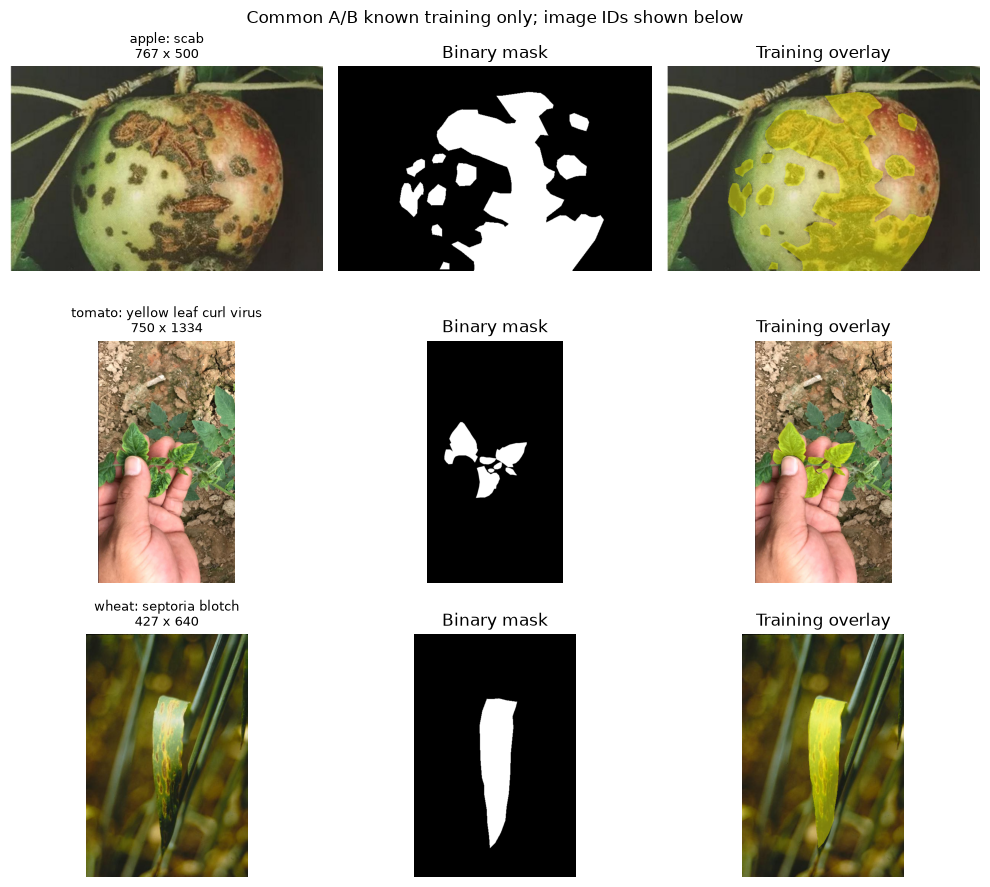

,image_id,host,disease
206,apple_scab_54.jpg,apple,scab
2296,tomato_yellow_leaf_curl_virus_45.jpg,tomato,yellow leaf curl virus
2983,wheat_septoria_blotch_blotch (73).jpg,wheat,septoria blotch


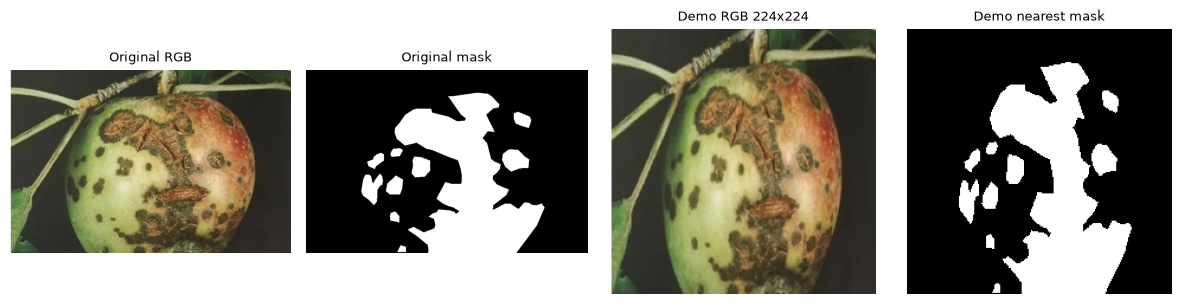

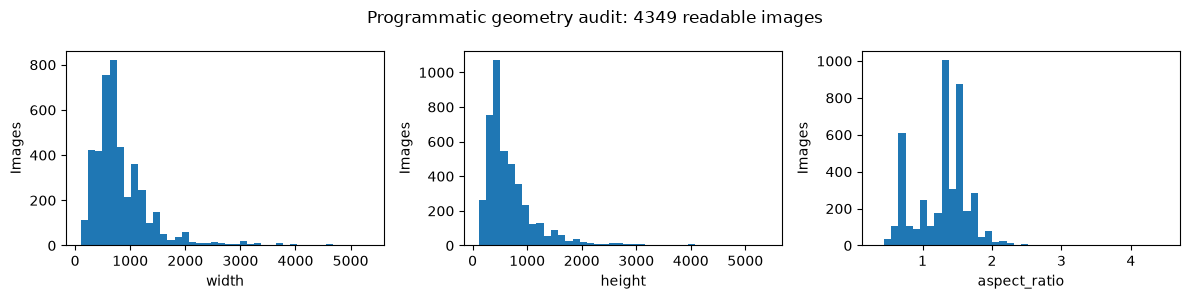

Paired resize demo: 224 x 224; binary values: [0, 1]


In [13]:
def load_training_pair(row, root):
    if not (row['included'] and row['mask_supervision_allowed'] and row['class_role']=='known'
            and row['original_split']=='training' and row['experimental_split']=='train'):
        raise ValueError('Mask access is only permitted for included known training')
    with Image.open(root/row['image_path']) as source:
        if source.getexif().get(274,1) != 1:
            raise ValueError('EXIF alignment requires review before mask supervision')
        rgb = source.convert('RGB')
    with Image.open(root/row['mask_path']) as source:
        values = np.array(source)
    expected = int(row['source_class_index'])+1
    if values.ndim != 2 or not set(np.unique(values)).issubset({0,expected}):
        raise ValueError('Unexpected mask encoding')
    mask = Image.fromarray((values==expected).astype(np.uint8))
    if rgb.size != mask.size:
        raise ValueError('Image/mask geometry mismatch; do not hide with resize')
    return rgb, mask

common = set(manifests["A"].loc[manifests["A"].mask_supervision_allowed, "image_id"]) & set(manifests["B"].loc[manifests["B"].mask_supervision_allowed, "image_id"])
candidates = manifests["A"].loc[manifests["A"].image_id.isin(common)]
assert not candidates.empty, "No common valid known-training examples."
examples = candidates.groupby("host", group_keys=False).sample(n=1, random_state=DISPLAY_SEED)
examples = examples.sample(n=min(3, len(examples)), random_state=DISPLAY_SEED).sort_values("host")
save_csv(examples[["image_id", "host", "disease", "original_split"]], ART / "metadata/display_sample_ids.csv")
fig, axes = plt.subplots(len(examples), 3, figsize=(10, 3 * len(examples)), squeeze=False)
for axs, row in zip(axes, examples.to_dict("records")):
    rgb, mask = load_training_pair(row, learn_data_root)
    axs[0].imshow(rgb); axs[0].set_title(f"{row['host']}: {row['disease']}\n{rgb.width} x {rgb.height}", fontsize=9)
    axs[1].imshow(mask, cmap="gray", vmin=0, vmax=1); axs[1].set_title("Binary mask")
    axs[2].imshow(rgb)
    axs[2].imshow(np.ma.masked_where(np.asarray(mask) == 0, np.asarray(mask)), cmap="autumn", alpha=.45, vmin=0, vmax=1)
    axs[2].set_title("Training overlay")
    for ax in axs: ax.axis("off")
fig.suptitle("Common A/B known training only; image IDs shown below")
fig.tight_layout(); fig.savefig(ART / "figures/known_training_examples.png", dpi=110)
plt.show(); plt.close(fig)
display(examples[["image_id", "host", "disease"]])
rgb, mask = load_training_pair(examples.iloc[0].to_dict(), learn_data_root)
resized_rgb = rgb.resize((224, 224), Image.Resampling.BILINEAR)
resized_mask = mask.resize((224, 224), Image.Resampling.NEAREST)
assert resized_rgb.size == resized_mask.size and set(np.unique(np.asarray(resized_mask))).issubset({0, 1})
fig, axes = plt.subplots(1, 4, figsize=(12, 3))
for ax, obj, title in zip(axes, [rgb, mask, resized_rgb, resized_mask], ["Original RGB", "Original mask", "Demo RGB 224x224", "Demo nearest mask"]):
    ax.imshow(obj, cmap="gray" if obj.mode != "RGB" else None)
    ax.set_title(title, fontsize=9); ax.axis("off")
fig.tight_layout(); fig.savefig(ART / "figures/paired_resize_demo.png", dpi=110)
plt.show(); plt.close(fig)
fig, axes = plt.subplots(1, 3, figsize=(12, 3))
for ax, column in zip(axes, ["width", "height", "aspect_ratio"]):
    ax.hist(readable_geometry[column], bins=40); ax.set(xlabel=column, ylabel="Images")
fig.suptitle(f"Programmatic geometry audit: {len(readable_geometry)} readable images")
fig.tight_layout(); fig.savefig(ART / "figures/image_geometry.png", dpi=110)
plt.show(); plt.close(fig)
print("Paired resize demo: 224 x 224; binary values:", np.unique(np.asarray(resized_mask)).tolist())

### 14. Export current CSVs and hash the draft protocol 导出当前 CSV 并对草稿协议做哈希 - Sections 2.2, 4.2, 5.1(5), 6.1

Overwrite stale generated outputs with the current audited results. Save canonical role mappings, IDs, manifests, exclusions and support counts. Hash the exported text files and read manifests back to verify round-trip integrity. Status remains draft until the team reviews these explicit rules and freezes both assignments before training.

用当前审查后的结果覆盖过期的生成输出。保存规范的角色映射、编号、清单、排除记录与支撑计数。对导出的文本文件做哈希，并回读清单以验证往返一致性。在团队复核这些明确规则、并在训练前冻结两项任务之前，状态仍为 draft。

In [14]:
save_csv(image_audit, ART / "metadata/images.csv")
save_csv(learn_host_counts.reset_index(), ART / "audit/host_counts.csv")
save_csv(learn_class_counts.reset_index(), ART / "audit/class_counts.csv")
save_csv(invalid_files, ART / "audit/invalid_files.csv")
save_csv(mask_issues, ART / "audit/mask_issues.csv")
save_csv(duplicate_groups, ART / "audit/duplicate_groups.csv")
save_csv(cross_partition_duplicates, ART / "audit/cross_partition_duplicates.csv")
save_csv(duplicate_exclusions, ART / "audit/duplicate_exclusions.csv")
exclusions = pd.concat([
    manifest.loc[~manifest.included, ["assignment", "image_id", "experimental_split", "exclusion_reason"]]
    for manifest in manifests.values()
], ignore_index=True)
save_csv(exclusions, ART / "audit/exclusions.csv")
save_json(ART / "audit/audit_summary.json", audit_summary)
save_json(ART / "metadata/dataset_info.json", dataset_info)
save_json(ART / "splits/disease_sort_order.json", {host: sorted(group.disease) for host, group in learn_classes.groupby("host")})
exported = []
for assignment, manifest in manifests.items():
    outputs = {
        f"class_roles_{assignment}.csv": roles[assignment],
        f"known_class_ids_{assignment}.csv": known_id_tables[assignment],
        f"manifest_{assignment}.csv": manifest,
        f"group_counts_{assignment}.csv": group_counts[assignment],
        f"class_support_{assignment}.csv": class_support[assignment].reset_index(),
        f"training_support_{assignment}.csv": training_support[assignment]
    }
    for filename, frame in outputs.items():
        path = ART / "splits" / filename
        save_csv(frame, path); exported.append(path)
    saved = pd.read_csv(ART / "splits" / f"manifest_{assignment}.csv", dtype={"known_class_id": "Int64"})
    assert saved.image_id.tolist() == manifest.image_id.tolist()
    assert saved.included.tolist() == manifest.included.tolist()
    assert saved.mask_supervision_allowed.tolist() == manifest.mask_supervision_allowed.tolist()
    assert saved.known_class_id.equals(manifest.known_class_id)

protocol = {
    "status": "draft", "created_at": RUN_AT, "dataset_version": "v7", "record_id": 17719108,
    "source_checksum_status": dataset_info["checksum_status"],
    "sorting": "lowercase disease, collapsed whitespace, exact host prefix removed; Unicode ascending",
    "original_partition_policy": "preserved; no random re-split or movement between partitions",
    "duplicate_policy": "exact pixel groups: test > validation > training; all conflicting-label members excluded; consistent same-partition copies retained",
    "duplicate_policy_origin": "project implementation choice, retained from the student's code; not mandated by the task sheet",
    "mask_policy": "known training only; class code = metadata Index+1, background=0; mask issues exclude the same training samples for both methods",
    "inference_inputs": "RGB only; filenames, host metadata and ground-truth masks are not predictive inputs",
    "loader_rule": "filter included == True AND experimental_split == requested split",
    "near_duplicates": "not checked; possible near-duplicate leakage remains a limitation",
    "unresolved_cross_partition_exact_duplicates_in_included_samples": 0,
    "freeze_blockers": ["Team review of deterministic duplicate and mask exclusions pending", "Full experiment and evaluation protocol must be agreed before training"] + (["Source inventory discrepancies need review"] if any(inventory.values()) else []),
    "file_sha256": {path.relative_to(ART).as_posix(): digest_file(path) for path in sorted(exported + [ART / "metadata/images.csv", ART / "audit/exclusions.csv", ART / "audit/duplicate_exclusions.csv", ART / "splits/disease_sort_order.json"])}
}
save_json(ART / "splits/split_protocol.json", protocol)
print("Updated A/B exports and exclusion files. Protocol status:", protocol["status"])

Updated A/B exports and exclusion files. Protocol status: draft


### 15. Handover and actual run summary 交接与实际运行摘要 - Sections 6.1, 6.5

Record actual outputs, counts, runtime and limitations. This completes the member-1 data pipeline, while model design/training/evaluation stay outside this notebook. The final coursework submission must integrate this preparation into one main notebook. AI assistance and remaining team decisions must be disclosed honestly.

记录实际输出、计数、运行时长与局限性。至此完成成员 1 的数据流水线，而模型设计/训练/评估仍在本笔记本之外。最终课业提交必须把本次数据准备整合进一个主笔记本。对 AI 辅助情况以及团队仍需作出的决定必须如实披露。

In [15]:
summary = {
    "run_at": RUN_AT, "elapsed_seconds": round(time.perf_counter() - START_TIME, 2),
    "dataset_version": "v7", "checksum_status": dataset_info["checksum_status"],
    "subset": {"hosts": int(image_audit.host.nunique()), "classes": len(learn_classes), "images": len(image_audit)},
    "audit": audit_summary, "manifest_status": protocol["status"],
    "duplicate_exclusion_rows": len(duplicate_exclusions),
    "included_counts": {assignment: {split: int(count) for split, count in manifest.loc[manifest.included].groupby("experimental_split").size().items()} for assignment, manifest in manifests.items()},
    "blockers": protocol["freeze_blockers"],
    "outputs": ["artifacts/metadata", "artifacts/audit", "artifacts/splits", "artifacts/figures"],
    "not_done": ["near-duplicate detection", "team protocol freeze", "model training", "test-performance evaluation"],
    "ai_assistance": {"tool": "Codex", "model_version": "not recorded", "tasks": ["interactive code tutoring", "notebook completion and English explanations", "task-sheet section matching", "execution and protocol checks"]}
}
save_json(ART / "metadata/execution_summary.json", summary)
display(summary)

{'run_at': '2026-11-19T12:04:20.271701+08:00',
 'elapsed_seconds': 48.08,
 'dataset_version': 'v7',
 'checksum_status': 'verified',
 'subset': {'hosts': 9, 'classes': 43, 'images': 4349},
 'audit': {'images': 4349,
  'hosts': 9,
  'classes': 43,
  'unreadable_images': 0,
  'mask_issues': 10,
  'file_duplicate_groups': 161,
  'pixel_duplicate_groups': 162,
  'cross_partition_duplicate_images': 151,
  'near_duplicate_check': 'not performed; unresolved near-duplicate leakage is a limitation',
  'pixel_hash_policy': 'EXIF transpose; original oriented dimensions + RGB pixels; no resizing'},
 'manifest_status': 'draft',
 'duplicate_exclusion_rows': 130,
 'included_counts': {'A': {'test': 673, 'train': 1704, 'validation': 376},
  'B': {'test': 623, 'train': 1547, 'validation': 370}},
 'blockers': ['Team review of deterministic duplicate and mask exclusions pending',
  'Full experiment and evaluation protocol must be agreed before training'],
 'outputs': ['artifacts/metadata',
  'artifacts/aud